# 02 — Préparation des données
Rapport : `reports/02_preprocessing_report.md`. La cible n'est jamais remplie ; `energy_filled` sert uniquement aux variables.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
from src.config import load_config
cfg = load_config()
R = ROOT / "reports"; FIG = R / "figures"
def load(name): return json.loads((R / name).read_text())
def fig(name): display(Image(filename=str(FIG / name)))

In [2]:
from src.data.preprocessing import load_processed
h = load_processed(cfg['data']['processed_dir'])
display(h.head()); display(h['fill_method'].value_counts().to_frame('heures'))

,n_valid,energy_kwh,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,observed,energy_filled,fill_method
timestamp,,,,,,,,,,,
2006-12-16 17:00:00,36,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN,unfilled
2006-12-16 18:00:00,60,3.632200,0.080033,234.580167,15.600000,0.0,403.0,1012.0,True,3.632200,observed
2006-12-16 19:00:00,60,3.400233,0.085233,233.232500,14.503333,0.0,86.0,1001.0,True,3.400233,observed
2006-12-16 20:00:00,60,3.268567,0.075100,234.071500,13.916667,0.0,0.0,1007.0,True,3.268567,observed
2006-12-16 21:00:00,60,3.056467,0.076667,237.158667,13.046667,0.0,25.0,1033.0,True,3.056467,observed


,heures
fill_method,
observed,34147
profile_4w,426
ffill,15
unfilled,1


## Journal des étapes

In [3]:
log = json.loads((Path(cfg['data']['processed_dir']) / 'preprocessing_log.json').read_text())
for s in log['steps']: print(s)

{'step': 'minute_grid', 'rows_in': 2075259, 'duplicates_dropped': 0, 'rows_out': 2075259, 'timestamps_added': 0, 'nan_rows': 25979}
{'step': 'hourly_aggregation', 'hours': 34589, 'complete': 34085, 'partial': 83, 'empty': 421, 'target_rule': 'energy_kwh = mean(P_kW over valid minutes) * 1 h', 'mean_cols': ['Global_reactive_power', 'Voltage', 'Global_intensity'], 'sum_cols_rescaled_to_60min': ['Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']}
{'step': 'validity_rule', 'min_valid_minutes': 50, 'observed': 34147, 'not_observed': 442, 'partial_hours_set_to_nan': 21}
{'step': 'causal_fill', 'short_gap_max_hours': 1, 'short_method': 'ffill', 'long_method': 'profile_4w', 'hours_filled_short': 16, 'hours_filled_long': 426, 'still_missing': 1, 'note': 'filled values feed lag features only; target is never imputed'}


## Choix n°1 : seuil de validité d'une heure (train)

,MAE_kwh,p90_abs_err_kwh,MAE_pct_of_mean
n_valid,,,
5,0.2835,0.7376,25.8968
10,0.2510,0.6582,22.9254
15,0.2289,0.6203,20.9054
20,0.1989,0.5467,18.1682
30,0.1491,0.4181,13.6211
40,0.1000,0.2768,9.1344
45,0.0749,0.2027,6.8389
50,0.0514,0.1411,4.6911
55,0.0272,0.0714,2.4803


seuil retenu : 50 minutes


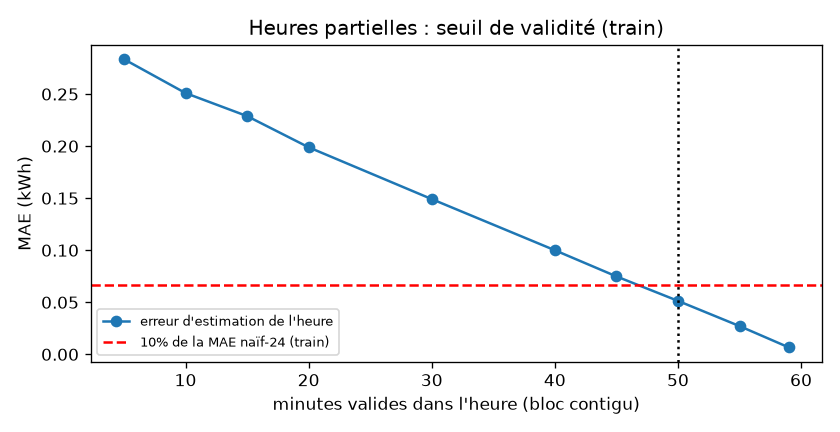

In [4]:
sel = log['selection']; display(pd.DataFrame(sel['partial_hour_error']).set_index('n_valid').round(4))
print('seuil retenu :', sel['min_valid_minutes'], 'minutes'); fig('02_partial_hour_threshold.png')

## Choix n°2 : méthode de remplissage causal (train, trous simulés)

,n_blocks,ffill,seasonal_24,seasonal_168,profile_4w,linear_offline (non causal)
gap_h,,,,,,
1,300,0.394,0.644,0.570,0.520,0.327
2,300,0.548,0.591,0.643,0.543,0.395
3,300,0.622,0.618,0.584,0.527,0.474
6,300,0.802,0.692,0.676,0.579,0.627
12,300,0.841,0.624,0.622,0.530,0.730
24,300,0.849,0.644,0.624,0.544,0.796
48,300,0.861,0.656,0.620,0.546,0.826
72,300,0.867,0.641,0.596,0.529,0.788
120,300,0.899,0.686,0.632,0.544,0.821


{'short_gap_max_hours': 1, 'short_method': 'ffill', 'long_method': 'profile_4w'}


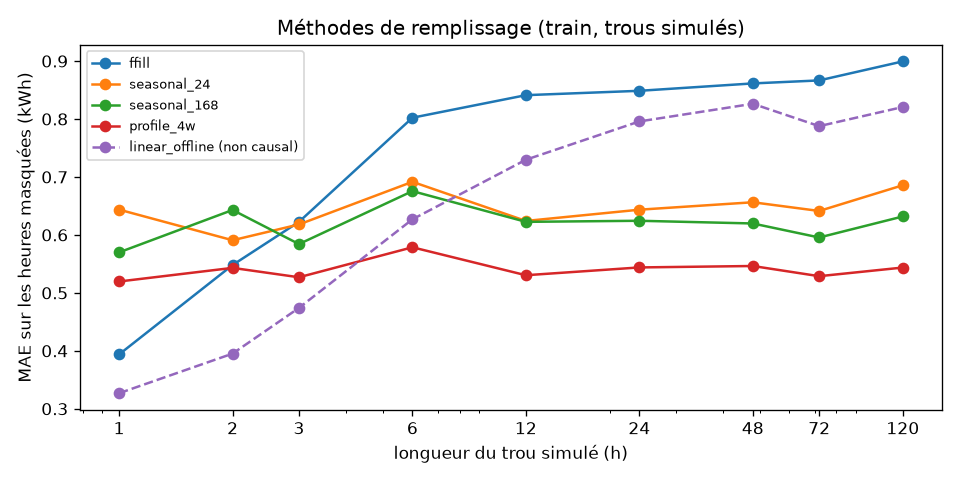

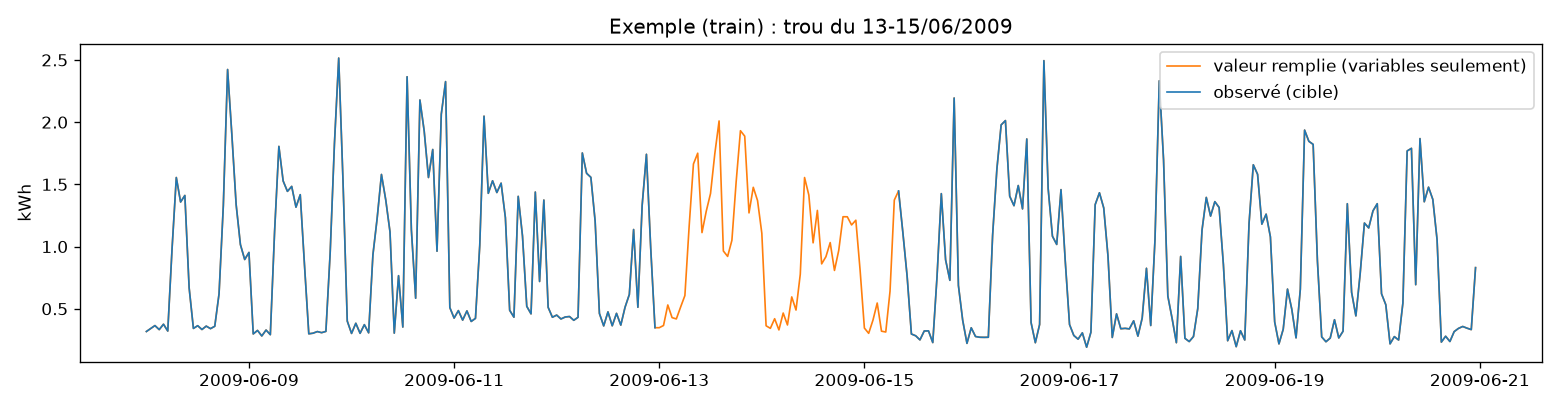

In [5]:
display(pd.DataFrame(sel['fill_scores_mae_kwh']).set_index('gap_h').round(3)); print(sel['policy'])
fig('02_fill_methods.png'); fig('02_fill_example.png')